# Experiment 181 · Replay on new checkpoint states

**Complete** · All paired checkpoint draws saved · 720/720 branches · 180/180 fully paired draws · ETA 0h 00m 00s

The primary readout is +256 arrivals. Secondary readouts are +96 and +1,000. Each intervention lasts 96 arrivals and is followed by fixed ¼×. Replay uses the first and every fourth slot with historical ages of 256–2,048 arrivals. Replacement replay swaps the current update in 24 slots. Additive replay keeps every current update and adds 24 replay updates. Extra current matches its update count and secondary masks with extra updates on current images. All updates use singleton batches.

The design uses 18 new, temporally separated positions, six per seed, and ten fresh paired masks per position. Positions are chosen from the gaps between Experiment 176 checkpoints without using the earlier measured advantages. The fixed unseen bank contains 512 frames from 32 clips disjoint from the training stream. The 128-frame historical bank and the unseen bank both use two fixed evaluation masks. Historical degradation is MSE after the rollout minus MSE at the shared starting checkpoint.

## Primary results at +256

| Comparison | Unseen gain | Historical degradation reduction | Unseen gain > 0 | Gain with historical excess ≤0.001 |
| --- | --- | --- | --- | --- |
 | Replace replay vs ¼× | +0.00501 [+0.00188, +0.00817] | +0.00425 [+0.00058, +0.00781] | 16/18 | 16/18 | 
 | Add replay vs ¼× | +0.00450 [+0.00171, +0.00746] | +0.00428 [+0.00103, +0.00768] | 14/18 | 13/18 | 
 | Add replay vs extra current | +0.00468 [+0.00126, +0.00818] | +0.00408 [+0.00017, +0.00795] | 14/18 | 13/18 | 

Effects average the paired masks within checkpoint, then weight checkpoints equally. Positive favors replay. The historical threshold compares replay with its reference. The final 95% intervals resample checkpoint means within seed and condition on these three seeds and the fixed evaluation banks. Intermediate results can have different numbers of completed draws per checkpoint.

| Arm | Unseen MSE | Historical degradation |
| --- | --- | --- |
 | quarter | 0.96506 | -0.07077 | 
 | replace-replay | 0.96004 | -0.07502 | 
 | add-replay | 0.96056 | -0.07505 | 
 | add-current | 0.96524 | -0.07097 | 


In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-replay-confirmation')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


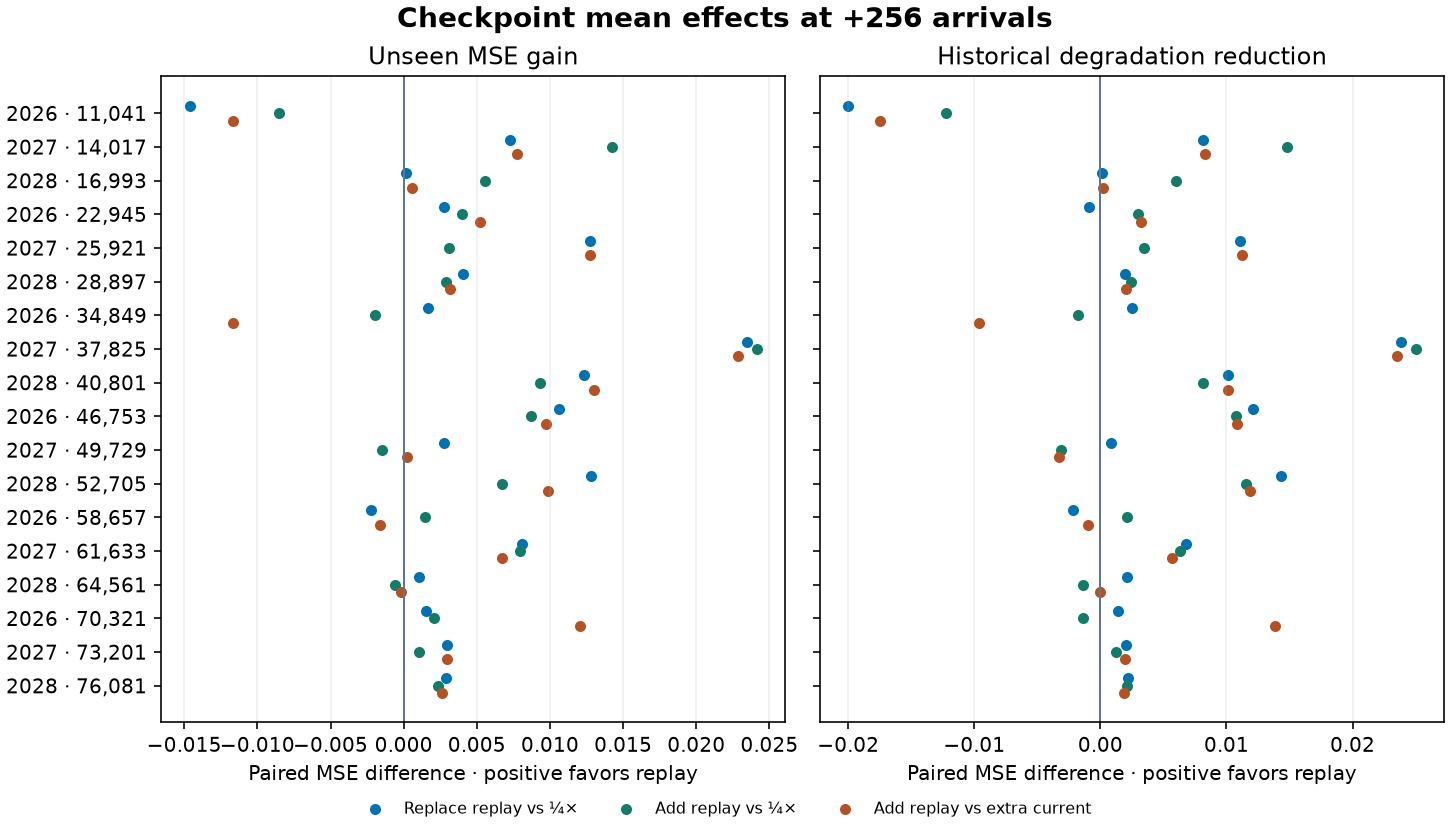

## Secondary readouts and diagnostics

| Arrivals | Comparison | Unseen gain | Historical gain | Recent-bank gain | RankMe gain | Median unseen mean / mask SD |
| --- | --- | --- | --- | --- | --- | --- |
 | 96 | Replace replay vs ¼× | +0.01301 [+0.00766, +0.01897] | +0.01372 [+0.00766, +0.02053] | -0.01016 [-0.01389, -0.00620] | +0.00242 [-0.02760, +0.02896] | +3.33 | 
 | 96 | Add replay vs ¼× | +0.01309 [+0.00919, +0.01721] | +0.01407 [+0.00973, +0.01867] | +0.00103 [-0.00157, +0.00401] | -0.00659 [-0.02918, +0.01314] | +5.42 | 
 | 96 | Add replay vs extra current | +0.01381 [+0.00864, +0.01960] | +0.01448 [+0.00885, +0.02093] | -0.00851 [-0.01176, -0.00494] | +0.00097 [-0.01956, +0.01992] | +4.54 | 
 | 256 | Replace replay vs ¼× | +0.00501 [+0.00188, +0.00817] | +0.00425 [+0.00058, +0.00781] | +0.00119 [-0.00172, +0.00399] | -0.00118 [-0.02827, +0.02476] | +2.28 | 
 | 256 | Add replay vs ¼× | +0.00450 [+0.00171, +0.00746] | +0.00428 [+0.00103, +0.00768] | +0.00261 [+0.00097, +0.00450] | -0.00964 [-0.03641, +0.01614] | +1.84 | 
 | 256 | Add replay vs extra current | +0.00468 [+0.00126, +0.00818] | +0.00408 [+0.00017, +0.00795] | +0.00031 [-0.00338, +0.00339] | +0.00266 [-0.02727, +0.02956] | +1.79 | 
 | 1000 | Replace replay vs ¼× | +0.00072 [-0.00153, +0.00288] | +0.00076 [-0.00122, +0.00257] | +0.00053 [-0.00236, +0.00452] | +0.00307 [-0.04169, +0.04520] | +0.02 | 
 | 1000 | Add replay vs ¼× | +0.00055 [-0.00082, +0.00184] | +0.00052 [-0.00076, +0.00182] | +0.00200 [-0.00059, +0.00579] | +0.00522 [-0.02786, +0.03935] | +0.06 | 
 | 1000 | Add replay vs extra current | -0.00040 [-0.00447, +0.00248] | +0.00029 [-0.00329, +0.00326] | -0.00140 [-0.00327, +0.00024] | -0.00399 [-0.04403, +0.03312] | +0.07 | 

### Unseen-loss action-order agreement

| Arrivals | ¼× / replace / add replay | ¼× / add replay / extra current |
| --- | --- | --- |
 | 96 | 88.7% | 94.7% | 
 | 256 | 81.7% | 80.7% | 
 | 1000 | 51.6% | 52.4% | 

### Compute and downstream probe

| Arm | Updates and gradient images at +1,000 | Mean training seconds | Scene probe Δ at +256 |
| --- | --- | --- | --- |
 | quarter | 1000 | 7.21 | +0.00 pp | 
 | replace-replay | 1000 | 7.19 | +0.04 pp | 
 | add-replay | 1024 | 7.34 | -0.12 pp | 
 | add-current | 1024 | 7.35 | -0.26 pp | 

The probe uses mask draw 1 at each checkpoint (18 complete) and the existing balanced three-way frozen-encoder scene split. Scene labels are used only for that diagnostic. Training times exclude readouts and probe fitting.

Saved pre-action features include recent reconstruction trends and recent-versus-historical embedding distance. Predictor fitting is deferred until the fixed replay effects are established.
